# 🔍 SubSense Audit v4 — Interactive Testing Notebook

Test the audit scoring system and live Claude conversation without going through Expo.

**Dependencies:** `pip install anthropic panel jupyter matplotlib python-dotenv`

**Setup:** Create a `.env` file in this directory with `ANTHROPIC_API_KEY=<your-anthropic-api-key>`

In [4]:
# ── Cell 1: Setup & Imports ────────────────────────────────────────────────
import os
import sys
import json
import importlib
from pathlib import Path

# Load .env from this directory
try:
    from dotenv import load_dotenv
    env_path = Path(os.path.dirname(os.path.abspath('__file__'))) / '.env'
    load_dotenv(dotenv_path=env_path)
    print(f"✅ .env loaded from {env_path}")
except ImportError:
    print("⚠️  python-dotenv not installed — set ANTHROPIC_API_KEY manually")

# Add this directory to path so we can import our modules
nb_dir = os.path.dirname(os.path.abspath('__file__'))
if nb_dir not in sys.path:
    sys.path.insert(0, nb_dir)

import audit_scorer as scorer
import audit_prompt as prompt
from audit_scorer import AuditSlots, ScoringContext, score_audit, format_score_result
from audit_prompt import AuditContext, AuditSlots as PromptSlots, ChatMessage, start_audit, continue_audit, format_response

import panel as pn
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

pn.extension()
matplotlib.rcParams['figure.figsize'] = (7, 4)

print("✅ All imports successful")
print(f"   anthropic key set: {'yes' if os.environ.get('ANTHROPIC_API_KEY') else 'NO — set ANTHROPIC_API_KEY'}")

✅ .env loaded from /Users/wanjiaruan/Desktop/sub/Docs/audit_testing/.env


✅ All imports successful
   anthropic key set: yes


---
## Part A — Deterministic Scorer Testing

No API calls needed. Adjust sliders to change scoring weights, then re-run the scorer.

In [5]:
# ── Cell 2: Scoring Parameter Panel (sliders) ──────────────────────────────
# All constants map directly to module-level variables in audit_scorer.py (v4).
# Click "Apply Parameters" to push slider values into the scorer module.

# Recommendation thresholds (v4: raised from 70/55/40 to 75/60/45)
sl_subscribe_now = pn.widgets.FloatSlider(name='Subscribe Now threshold', start=65, end=95, step=1, value=75)
sl_start_trial   = pn.widgets.FloatSlider(name='Start Trial threshold',   start=50, end=80, step=1, value=60)
sl_watchlist     = pn.widgets.FloatSlider(name='Watchlist threshold',      start=30, end=60, step=1, value=45)

# Need Fit (v4: motivation_clarity-based, not category keyword)
sl_scenario_specific = pn.widgets.FloatSlider(name='Need Fit — scenario_specific (specific time/place/workflow)', start=18, end=25, step=0.5, value=22)
sl_problem_aware     = pn.widgets.FloatSlider(name='Need Fit — problem_aware (named a gap/pain)',                start=12, end=22, step=0.5, value=18)
sl_category_only     = pn.widgets.FloatSlider(name='Need Fit — category_only (just picked a chip)',              start=8,  end=18, step=0.5, value=14)
sl_need_none         = pn.widgets.FloatSlider(name='Need Fit — none/not_sure',                                  start=5,  end=15, step=0.5, value=10)

# Budget Fit (v4: feel-FIRST base, max 20 not 25)
sl_budget_comfortable = pn.widgets.FloatSlider(name='Budget base — comfortable', start=14, end=20, step=0.5, value=18)
sl_budget_tight       = pn.widgets.FloatSlider(name='Budget base — tight',       start=5,  end=15, step=0.5, value=10)
sl_budget_no_way      = pn.widgets.FloatSlider(name='Budget base — no_way',      start=0,  end=8,  step=0.5, value=3)

# Risk (v4: redesigned options, max 15 not 10)
sl_risk_none     = pn.widgets.FloatSlider(name='Risk — none',           start=12, end=15, step=0.5, value=15)
sl_risk_free     = pn.widgets.FloatSlider(name='Risk — free_enough',    start=7,  end=13, step=0.5, value=10)
sl_risk_forget   = pn.widgets.FloatSlider(name='Risk — forget_cancel',  start=4,  end=10, step=0.5, value=7)
sl_risk_interest = pn.widgets.FloatSlider(name='Risk — interest_decay', start=3,  end=9,  step=0.5, value=6)
sl_risk_impulse  = pn.widgets.FloatSlider(name='Risk — impulse',        start=1,  end=7,  step=0.5, value=4)

# Uncertainty (v4: per-slot weighted, not flat -2)
sl_ns_max = pn.widgets.FloatSlider(name='Uncertainty penalty max', start=5, end=15, step=1, value=10)

def apply_sliders(event=None):
    scorer.SUBSCRIBE_NOW_THRESHOLD = sl_subscribe_now.value
    scorer.START_TRIAL_THRESHOLD   = sl_start_trial.value
    scorer.WATCHLIST_THRESHOLD     = sl_watchlist.value

    scorer.NEED_FIT_SCENARIO_SPECIFIC = sl_scenario_specific.value
    scorer.NEED_FIT_PROBLEM_AWARE     = sl_problem_aware.value
    scorer.NEED_FIT_CATEGORY_ONLY     = sl_category_only.value
    scorer.NEED_FIT_NONE              = sl_need_none.value

    scorer.BUDGET_FEEL_BASE = {
        "comfortable": sl_budget_comfortable.value,
        "tight":       sl_budget_tight.value,
        "no_way":      sl_budget_no_way.value,
        "not_sure":    sl_budget_tight.value,   # not_sure = same as tight
    }

    scorer.RISK_SCORE = {
        "none":           sl_risk_none.value,
        "free_enough":    sl_risk_free.value,
        "forget_cancel":  sl_risk_forget.value,
        "interest_decay": sl_risk_interest.value,
        "not_sure":       5.0,
        "impulse":        sl_risk_impulse.value,
    }

    scorer.UNCERTAINTY_PENALTY_MAX = sl_ns_max.value
    print("✅ v4 parameters applied")

btn_apply = pn.widgets.Button(name='Apply Parameters', button_type='primary')
btn_apply.on_click(apply_sliders)

pn.Column(
    pn.pane.Markdown("### v4 Scoring Parameters"),
    pn.pane.Markdown("**Recommendation Thresholds** (v4 baseline: 75 / 60 / 45)"),
    sl_subscribe_now, sl_start_trial, sl_watchlist,
    pn.pane.Markdown("**Need Fit — motivation_clarity** (v4 max: 25)"),
    sl_scenario_specific, sl_problem_aware, sl_category_only, sl_need_none,
    pn.pane.Markdown("**Budget Fit — feel-first base** (v4 max: 20)"),
    sl_budget_comfortable, sl_budget_tight, sl_budget_no_way,
    pn.pane.Markdown("**Independent Risk** (v4 max: 15, new options)"),
    sl_risk_none, sl_risk_free, sl_risk_forget, sl_risk_interest, sl_risk_impulse,
    pn.pane.Markdown("**Uncertainty**"),
    sl_ns_max,
    btn_apply,
    width=600
)

BokehModel(combine_events=True, render_bundle={'docs_json': {'33f97999-19bf-4b16-a0a9-fce9c2eaaac4': {'version…

In [6]:
# ── Cell 3: Quick Score Test (single scenario) ─────────────────────────────
# Edit these values to test any scenario manually.
# All field names match AuditSlots v4 (audit_scorer.py).

test_slots = AuditSlots(
    service_name        = "Spotify",
    price               = 9.99,
    billing_cycle       = "monthly",
    price_monthly       = 9.99,
    # Stage 2 — history
    history_status      = "first_time",   # first_time | cancelled | upgrading | free_trial
    # Stage 3 — motivation
    motivation_clarity  = "scenario_specific",  # scenario_specific | problem_aware | category_only | none
    primary_motivation  = "entertainment",
    # Stage 4 — usage
    expected_frequency  = 4.5,            # 0 | 1 | 2.5 | 4.5 | 7 | None (not_sure)
    # Stage 5 — budget
    budget_feel         = "comfortable",  # comfortable | tight | no_way | not_sure
    # Stage 6 — overlap
    overlap_level       = "none",         # none | some | significant | high | not_sure
    # Stage 7 — risk (v4 options)
    top_risk            = "none",         # none | free_enough | forget_cancel | interest_decay | impulse | not_sure
)

test_ctx = ScoringContext(
    slots                   = test_slots,
    monthly_budget          = 500,
    price_sensitivity       = 0.3,          # 0.0 (price-blind) → 1.0 (very sensitive)
    existing_subscriptions  = [],
    category                = "entertainment",  # entertainment | productivity | health | learning | social | creative | utilities
    persona_alignment_coeff = 1.0,          # 0.7–1.3 (interest tag match)
    lifecycle_coeff         = 1.0,          # 0.6–1.1 (from history_status)
    same_category_count     = 0,            # # same-category subs already owned
    same_category_avg_usage = 1.0,          # avg usage rate (0–1) for portfolio pattern check
)

result = score_audit(test_ctx)
print(format_score_result(result))

Score               : 95.0 / 100
Recommendation      : SUBSCRIBE_NOW
Uncertainty         : low (not_sure ×0)

  Breakdown (v4 weights: NeedFit/25, Usage/25, Budget/20, Overlap/15, Risk/15):
  need_fit            : 22.0 / 25
  usage               : 23.0 / 25
  budget_fit          : 20.0 / 20
  overlap             : 15.0 / 15
  risk                : 15.0 / 15
  uncertainty_penalty : -0.0


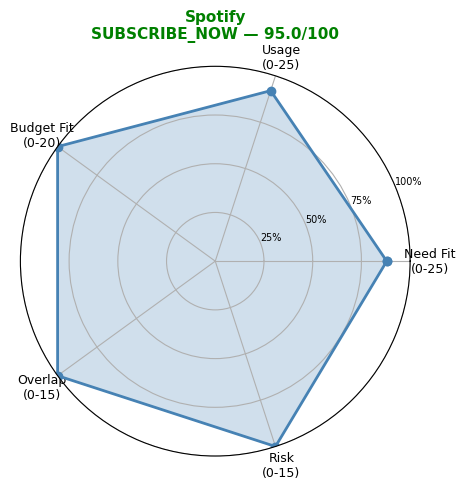

In [7]:
# ── Cell 4: Score Radar Chart ──────────────────────────────────────────────

def plot_score_radar(result, title="Score Breakdown"):
    b = result.breakdown
    # v4 weights: NeedFit/25, Usage/25, Budget/20, Overlap/15, Risk/15
    labels = ['Need Fit\n(0-25)', 'Usage\n(0-25)', 'Budget Fit\n(0-20)', 'Overlap\n(0-15)', 'Risk\n(0-15)']
    maxes  = [25, 25, 20, 15, 15]
    values = [b.need_fit, b.usage, b.budget_fit, b.overlap, b.risk]
    normed = [v / m for v, m in zip(values, maxes)]

    N = len(labels)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    normed += normed[:1]
    angles += angles[:1]

    fig, ax = plt.subplots(subplot_kw={'polar': True}, figsize=(5, 5))
    ax.plot(angles, normed, 'o-', linewidth=2, color='steelblue')
    ax.fill(angles, normed, alpha=0.25, color='steelblue')
    ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=7)

    # Show cross-validation adjustments if any
    cv_notes = []
    if b.need_fit_cv_adj != 0:
        cv_notes.append(f"NF CV{b.need_fit_cv_adj:+.0f}")
    if b.usage_cv_adj != 0:
        cv_notes.append(f"U CV{b.usage_cv_adj:+.0f}")
    cv_str = f" ({', '.join(cv_notes)})" if cv_notes else ""

    rec = result.recommendation_type
    color_map = {'subscribe_now': 'green', 'start_trial': 'dodgerblue', 'watchlist': 'orange', 'alternative': 'red'}
    ax.set_title(f"{title}\n{rec.upper()} — {result.total:.1f}/100{cv_str}",
                 fontsize=11, fontweight='bold', color=color_map.get(rec, 'black'), pad=20)
    plt.tight_layout()
    plt.show()

plot_score_radar(result, title=test_slots.service_name or "Test")

---
## Part B — Batch Test Runner

Run all 15 predefined scenarios from `test_scenarios.py` and see pass/fail.

In [8]:
# ── Cell 5: Batch Test Runner ──────────────────────────────────────────────
import test_scenarios as ts
importlib.reload(ts)   # pick up any edits to test_scenarios.py

rows = ts.run_batch(verbose=True)


  ID  Description                                                       Expected           Actual   Score  Pass?
----------------------------------------------------------------------------------------------------------------
 S01  Spec validation: 每天用，预算舒适，无重叠，无风险 → ≥85                      subscribe_now    subscribe_now    97.0  ✅ PASS
 S02  Work tool — specific scenario, daily use, strong persona     subscribe_now    subscribe_now   100.0  ✅ PASS
 S03  Learning platform — problem_aware motivation, 4-5x/wk → S    subscribe_now    subscribe_now    91.0  ✅ PASS
 S04  Premium explorer — upgrading plan, high persona match, no    subscribe_now    subscribe_now    98.0  ✅ PASS
 S05  Spec validation: 动机模糊，每周一次，预算紧张，有些重叠 → 50-65 (v4: watchli        watchlist        watchlist    51.0  ✅ PASS
 S06  Free trial history, not sure on frequency, budget OK → St      start_trial      start_trial    69.0  ✅ PASS
 S07  Medium motivation clarity, moderate usage, some overlap,       start_trial      sta

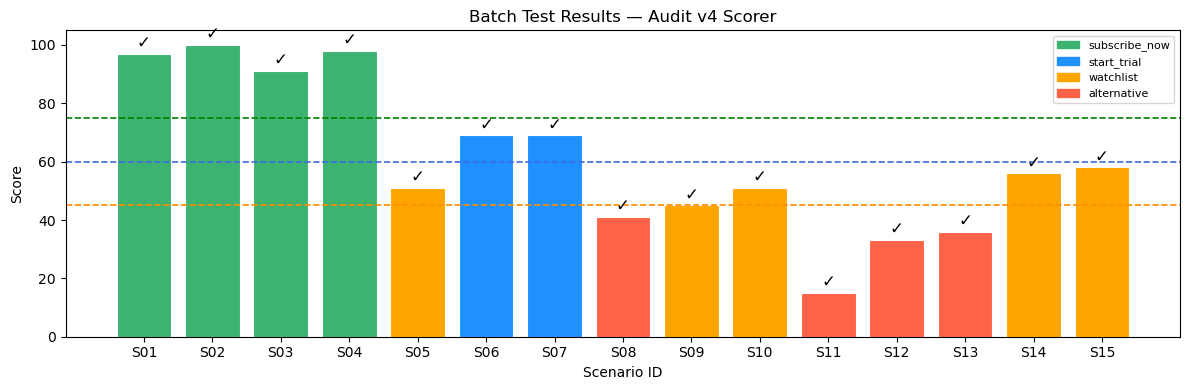

In [9]:
# ── Cell 6: Batch Results Bar Chart ───────────────────────────────────────

def plot_batch_results(rows):
    ids     = [r['id'] for r in rows]
    scores  = [r['score'] for r in rows]
    passed  = [r['passed'] for r in rows]
    recs    = [r['actual_rec'] for r in rows]

    color_map = {
        'subscribe_now': 'mediumseagreen',
        'start_trial':   'dodgerblue',
        'watchlist':     'orange',
        'alternative':   'tomato',
    }
    colors = [color_map.get(r, 'gray') for r in recs]

    fig, ax = plt.subplots(figsize=(12, 4))
    bars = ax.bar(ids, scores, color=colors, edgecolor='white', linewidth=0.8)

    # v4 threshold lines
    ax.axhline(scorer.SUBSCRIBE_NOW_THRESHOLD, color='green',     linestyle='--', lw=1.2, label=f'Subscribe Now ({scorer.SUBSCRIBE_NOW_THRESHOLD})')
    ax.axhline(scorer.START_TRIAL_THRESHOLD,   color='royalblue', linestyle='--', lw=1.2, label=f'Start Trial ({scorer.START_TRIAL_THRESHOLD})')
    ax.axhline(scorer.WATCHLIST_THRESHOLD,     color='darkorange',linestyle='--', lw=1.2, label=f'Watchlist ({scorer.WATCHLIST_THRESHOLD})')

    # Mark pass/fail
    for i, (bar, ok) in enumerate(zip(bars, passed)):
        marker = '✓' if ok else '✗'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                marker, ha='center', va='bottom', fontsize=12,
                color='black' if ok else 'red', fontweight='bold')

    # Legend
    legend_patches = [mpatches.Patch(color=c, label=l) for l, c in [
        ('subscribe_now', 'mediumseagreen'), ('start_trial', 'dodgerblue'),
        ('watchlist', 'orange'), ('alternative', 'tomato')
    ]]
    ax.legend(handles=legend_patches, loc='upper right', fontsize=8)
    ax.set_ylim(0, 105)
    ax.set_xlabel('Scenario ID')
    ax.set_ylabel('Score')
    ax.set_title('Batch Test Results — Audit v4 Scorer')
    plt.tight_layout()
    plt.show()

plot_batch_results(rows)

---
## Part C — Live Conversation Simulator

Chat with the actual Claude API using the v3 system prompt. Slots are extracted turn by turn.

In [10]:
# ── Cell 7: Persona Setup ──────────────────────────────────────────────────
# These variables are used by the Conversation Simulator (Cell 8) and compute_score().

persona_name                    = "Alex"
persona_budget                  = 50.0        # monthly subscription budget ($)
persona_price_sensitivity       = 0.3          # 0.0 (price-blind) → 1.0 (very sensitive)

# v4 new: ScoringContext fields
persona_category                = "entertainment"  # service category (for cost-per-use benchmark)
persona_alignment_coeff         = 1.0          # 0.7–1.3: persona interest tag match to service
persona_lifecycle_coeff         = 1.0          # 0.6–1.1: derived from history_status
persona_same_category_count     = 0            # how many same-category subs already owned
persona_same_category_avg_usage = 1.0          # avg check-in usage rate of those subs (0–1)

persona_existing_subs = [
    {"name": "Spotify",  "cost": 9.99,  "category": "entertainment"},
    {"name": "Netflix",  "cost": 15.99, "category": "entertainment"},
]

print(f"Persona: {persona_name}")
print(f"  Monthly budget:           ${persona_budget}")
print(f"  Price sensitivity:        {persona_price_sensitivity}")
print(f"  Service category:         {persona_category}")
print(f"  Persona alignment coeff:  {persona_alignment_coeff}  (0.7–1.3)")
print(f"  Lifecycle coeff:          {persona_lifecycle_coeff}  (0.6–1.1)")
print(f"  Same-category subs:       {persona_same_category_count}  (avg usage: {persona_same_category_avg_usage})")
print(f"  Existing subs:            {persona_existing_subs or 'None'}")

Persona: Alex
  Monthly budget:           $50.0
  Price sensitivity:        0.3
  Service category:         entertainment
  Persona alignment coeff:  1.0  (0.7–1.3)
  Lifecycle coeff:          1.0  (0.6–1.1)
  Same-category subs:       0  (avg usage: 1.0)
  Existing subs:            [{'name': 'Spotify', 'cost': 9.99, 'category': 'entertainment'}, {'name': 'Netflix', 'cost': 15.99, 'category': 'entertainment'}]


In [11]:
# ── Cell 8 修复版：Conversation Simulator (Panel UI) ──────────────────────

# 修复：最后一个问题重复的bug
# 问题：advance_stage() 只能前进到 stage_idx=6，完成检查逻辑有误
# 解决：允许 stage_idx 到达 7（超出数组），并在正确的时机检查完成

STAGES = [
    "service_price",
    "history_check",
    "motivation",
    "expected_usage",
    "budget_feel",
    "overlap_decision",
    "independent_risk",
]

state = {
    "history":      [],
    "slots":        {},
    "stage_idx":    0,
    "turn_index":   0,
    "last_response": None,
    "finished":     False,
}

_START_TRIGGER = "Start the audit. Ask me what service I am thinking of subscribing to."

def make_audit_ctx() -> AuditContext:
    s = state["slots"]
    slots_obj = PromptSlots(
        service_name              = s.get("service_name"),
        price                     = s.get("price"),
        billing_cycle             = s.get("billing_cycle"),
        price_monthly             = s.get("price_monthly"),
        history_status            = s.get("history_status"),
        cancel_reason             = s.get("cancel_reason"),
        free_trial_limiting       = s.get("free_trial_limiting"),
        history_source            = s.get("history_source"),
        previous_duration_months  = s.get("previous_duration_months"),
        primary_motivation        = s.get("primary_motivation"),
        motivation_note           = s.get("motivation_note"),
        motivation_clarity        = s.get("motivation_clarity"),
        expected_frequency        = s.get("expected_frequency"),
        budget_feel               = s.get("budget_feel"),
        overlap_level             = s.get("overlap_level"),
        top_risk                  = s.get("top_risk"),
        additional_risk_note      = s.get("additional_risk_note"),
    )
    
    # 修复：如果已经完成所有stage，stage_idx会是7（超出数组）
    # 此时使用最后一个stage名称作为context
    current_stage = STAGES[state["stage_idx"]] if state["stage_idx"] < len(STAGES) else STAGES[-1]
    
    return AuditContext(
        stage                  = current_stage,
        turn_index             = state["turn_index"],
        slots                  = slots_obj,
        monthly_budget         = persona_budget,
        persona                = {"price_sensitivity": persona_price_sensitivity},
        existing_subscriptions = persona_existing_subs,
        user_name              = persona_name,
    )

def advance_stage(resp):
    """Move to next stage when current stage's key slot is filled."""
    stage_required = {
        "service_price":    ["service_name"],
        "history_check":    ["history_status"],
        "motivation":       ["primary_motivation"],
        "expected_usage":   ["expected_frequency"],
        "budget_feel":      ["budget_feel"],
        "overlap_decision": ["overlap_level"],
        "independent_risk": ["top_risk"],
    }
    
    # 修复：允许检查所有stage，包括最后一个
    if state["stage_idx"] < len(STAGES):
        current_stage = STAGES[state["stage_idx"]]
        required = stage_required.get(current_stage, [])
        
        if all(state["slots"].get(r) is not None for r in required):
            # 修复：允许前进到 stage_idx = len(STAGES)（即7），表示完成
            next_idx = state["stage_idx"] + 1
            
            # Special: if upgrading, skip expected_usage (stage idx 3)
            if (next_idx < len(STAGES) and 
                STAGES[next_idx] == "expected_usage" and 
                state["slots"].get("history_status") == "upgrading"):
                next_idx += 1
            
            state["stage_idx"] = next_idx
            
            # 修复：如果前进到了 stage_idx = 7，标记为完成
            if state["stage_idx"] >= len(STAGES):
                state["finished"] = True

def compute_score():
    s = state["slots"]
    slots_obj = AuditSlots(
        service_name             = s.get("service_name"),
        price                    = s.get("price"),
        billing_cycle            = s.get("billing_cycle"),
        price_monthly            = s.get("price_monthly"),
        history_status           = s.get("history_status"),
        motivation_clarity       = s.get("motivation_clarity"),
        primary_motivation       = s.get("primary_motivation"),
        expected_frequency       = s.get("expected_frequency"),
        budget_feel              = s.get("budget_feel"),
        overlap_level            = s.get("overlap_level"),
        top_risk                 = s.get("top_risk"),
    )
    ctx = ScoringContext(
        slots                   = slots_obj,
        monthly_budget          = persona_budget,
        price_sensitivity       = persona_price_sensitivity,
        existing_subscriptions  = persona_existing_subs,
        category                = persona_category,
        persona_alignment_coeff = persona_alignment_coeff,
        lifecycle_coeff         = persona_lifecycle_coeff,
        same_category_count     = persona_same_category_count,
        same_category_avg_usage = persona_same_category_avg_usage,
    )
    return score_audit(ctx)

# ── Widgets ────────────────────────────────────────────────────────────────
inp          = pn.widgets.TextInput(placeholder="Type your reply here…", width=550)
btn_start    = pn.widgets.Button(name="Start Audit", button_type="success", width=120)
btn_send     = pn.widgets.Button(name="Send", button_type="primary", width=80, disabled=True)
btn_reset    = pn.widgets.Button(name="Reset", button_type="danger", width=80)

chat_output  = pn.pane.Markdown("", width=700,
    styles={"background": "#f8f8f8", "padding": "10px", "color": "black"})
slot_output  = pn.pane.Markdown("", width=340,
    styles={"background": "#eef4fb", "padding": "10px", "color": "black"})
score_output = pn.pane.Markdown("", width=340,
    styles={"background": "#eef4fb", "color": "black"})
status_bar   = pn.pane.Markdown("", width=700,
    styles={"background": "#eef4fb", "color": "black"})

chat_lines = []

def render_slots():
    lines = ["**Current Slots (v4)**\n", "| Slot | Value |", "|---|---|"]
    for k, v in state["slots"].items():
        lines.append(f"| {k} | {v} |")
    if not state["slots"]:
        lines.append("| — | — |")
    
    # 修复：显示正确的stage信息
    if state["stage_idx"] < len(STAGES):
        stage_name = STAGES[state['stage_idx']]
        lines.append(f"\nStage: **{stage_name}** ({state['stage_idx']+1}/{len(STAGES)})")
    else:
        lines.append(f"\n✅ **All stages complete!** ({len(STAGES)}/{len(STAGES)})")
    
    slot_output.object = "\n".join(lines)

def render_score():
    result = compute_score()
    b = result.breakdown
    rec_emoji = {"subscribe_now": "✅", "start_trial": "🔵", "watchlist": "⚠️", "alternative": "❌"}
    cv_notes = []
    if b.need_fit_cv_adj != 0:
        cv_notes.append(f"NF CV{b.need_fit_cv_adj:+.0f}")
    if b.usage_cv_adj != 0:
        cv_notes.append(f"U CV{b.usage_cv_adj:+.0f}")
    cv_str = f" ({', '.join(cv_notes)})" if cv_notes else ""
    lines = [
        f"**Score: {result.total:.1f}/100**",
        f"{rec_emoji.get(result.recommendation_type, '')} **{result.recommendation_type.upper()}**",
        f"Uncertainty: {result.uncertainty_level} (×{result.not_sure_count})",
        "", "| Dimension | Score |", "|---|---|",
        f"| Need Fit       | {b.need_fit:.1f}/25{cv_str} |",
        f"| Usage          | {b.usage:.1f}/25 |",
        f"| Budget Fit     | {b.budget_fit:.1f}/20 |",
        f"| Overlap        | {b.overlap:.1f}/15 |",
        f"| Risk           | {b.risk:.1f}/15 |",
        f"| Uncertainty −  | {b.uncertainty_penalty:.1f} |",
    ]
    score_output.object = "\n".join(lines)

def append_chat(role, text):
    prefix = f"**{persona_name}:** " if role == "user" else "**SubSense AI:** "
    chat_lines.append(f"{prefix}{text}\n")
    chat_output.object = "\n---\n".join(chat_lines[-20:])

def handle_response(resp):
    state["last_response"] = resp
    state["turn_index"] += 1
    
    # Merge slots_delta into state
    for k, v in resp.slots_delta.items():
        state["slots"][k] = v
    
    # Derive price_monthly
    if state["slots"].get("price") and state["slots"].get("billing_cycle") == "monthly":
        state["slots"]["price_monthly"] = state["slots"]["price"]
    elif state["slots"].get("price") and state["slots"].get("billing_cycle") == "yearly":
        state["slots"]["price_monthly"] = round(state["slots"]["price"] / 12, 2)
    
    # 修复：先前进stage，再检查是否完成
    advance_stage(resp)
    
    # Build display text
    parts = []
    for b in resp.bubbles:
        parts.append(b)
    if resp.aha.get("triggered") and resp.aha.get("bubbles"):
        parts.append(f"⚡ {resp.aha['bubbles'][0]}")
    if resp.question:
        parts.append(resp.question)
    if resp.options:
        opts = " | ".join(f"[{o.label}]" for o in resp.options)
        parts.append(f"*Options: {opts}*")
    if resp.ui.get("input_mode") == "slider":
        parts.append("*[Slider: Rarely → Daily]*")
    
    append_chat("assistant", "  \n".join(parts))
    render_slots()
    render_score()
    
    # Flags
    flags = resp.flags
    flag_notes = []
    if flags.get("contradiction"):       flag_notes.append("⚠️ contradiction")
    if flags.get("off_topic"):           flag_notes.append("🚫 off-topic")
    if flags.get("price_cycle_unclear"): flag_notes.append("❓ price cycle unclear")
    if resp.aha.get("triggered"):        flag_notes.append("⚡ aha triggered")
    
    # 修复：检查是否完成（在advance_stage之后）
    if state["finished"]:
        btn_send.disabled = True
        status_bar.object = "✅ Audit complete (7/7 stages)! See score breakdown →"
    elif flag_notes:
        status_bar.object = "  ".join(flag_notes)
    else:
        status_bar.object = ""

def on_start(event):
    btn_send.disabled = False
    ctx = make_audit_ctx()
    status_bar.object = "⏳ Starting audit..."
    resp = start_audit(ctx)
    assistant_text = " ".join(resp.bubbles)
    if resp.question:
        assistant_text += " " + resp.question
    # 修复：添加触发消息到历史
    state["history"].append(ChatMessage(role="user", content=_START_TRIGGER))
    state["history"].append(ChatMessage(role="assistant", content=assistant_text))
    handle_response(resp)
    status_bar.object = "Type your reply and click Send."

def on_send(event):
    # 修复：读取两个可能的值
    user_text = (inp.value or inp.value_input or "").strip()
    # print(f"[on_send] value={repr(inp.value)!r}  value_input={repr(inp.value_input)!r}  → using: {repr(user_text)}")
    if not user_text:
        status_bar.object = "⚠️ No text to send — type something first."
        return
    inp.value = ""
    append_chat("user", user_text)
    state["history"].append(ChatMessage(role="user", content=user_text))
    # print(f"[on_send] history len={len(state['history'])}, roles={[m.role for m in state['history']]}")
    ctx = make_audit_ctx()
    status_bar.object = "⏳ Thinking..."
    resp = continue_audit(state["history"], ctx)
    # print(f"[on_send] slots_delta={resp.slots_delta}  stage={resp.stage}")
    assistant_text = " ".join(resp.bubbles)
    if resp.question:
        assistant_text += " " + resp.question
    state["history"].append(ChatMessage(role="assistant", content=assistant_text))
    handle_response(resp)

def on_reset(event):
    state["history"].clear()
    state["slots"].clear()
    state["stage_idx"] = 0
    state["turn_index"] = 0
    state["last_response"] = None
    state["finished"] = False
    chat_lines.clear()
    chat_output.object = ""
    slot_output.object = ""
    score_output.object = ""
    status_bar.object = ""
    inp.value = ""
    btn_send.disabled = True

btn_start.on_click(on_start)
btn_send.on_click(on_send)
btn_reset.on_click(on_reset)

# ── Layout ─────────────────────────────────────────────────────────────────
controls  = pn.Row(btn_start, btn_reset)
input_row = pn.Row(inp, btn_send)
left_panel  = pn.Column(controls, chat_output, input_row, status_bar, width=720)
right_panel = pn.Column(slot_output, score_output, width=360)

render_slots()
render_score()

pn.Row(left_panel, right_panel)

BokehModel(combine_events=True, render_bundle={'docs_json': {'33f7944a-a36f-4bc4-9e27-204dc7490268': {'version…

---
## Part D — Debug Helpers

In [12]:
# 查看最后一次 Claude 响应
if 'state' in locals() and state.get("last_response"):
    resp = state["last_response"]
    print("=== Last Response ===")
    print(f"Stage: {resp.stage}")
    print(f"Turn: {resp.turn_index}")
    print(f"Slots Delta: {resp.slots_delta}")
    print(f"Question: {resp.question}")
    print(f"\nFlags: {resp.flags}")
else:
    print("No response captured")

No response captured


In [13]:
# ── Debug: Test continue_audit directly (no Panel) ─────────────────────────
# Run this cell AFTER restarting kernel & running all cells.
# This bypasses Panel so you can see print output directly.

importlib.reload(prompt)
from audit_prompt import AuditContext, AuditSlots as PS, ChatMessage, continue_audit

test_history = [
    ChatMessage(role="user",      content="Start the audit. Ask me what service I am thinking of subscribing to."),
    ChatMessage(role="assistant", content="What service are you considering, and what's the cost?"),
    ChatMessage(role="user",      content="disney+, 11.99 monthly"),
]

test_ctx = AuditContext(
    stage="service_price",
    turn_index=1,
    slots=PS(),
    monthly_budget=50.0,
    persona={"price_sensitivity": 0.3},
    existing_subscriptions=[],
    user_name="Alex",
)

resp = continue_audit(test_history, test_ctx)
print(f"\n=== Result ===")
print(f"slots_delta : {resp.slots_delta}")
print(f"stage       : {resp.stage}")
print(f"question    : {resp.question}")


=== Result ===
slots_delta : {'service_name': 'Disney+', 'price': 11.99, 'billing_cycle': 'monthly', 'price_monthly': 11.99}
stage       : history_check
question    : Have you used Disney+ before?


In [14]:
# ── Cell 9: Inspect last Claude response ──────────────────────────────────
if state.get("last_response"):
    print(format_response(state["last_response"]))
else:
    print("No response yet — run Part C first.")

No response yet — run Part C first.


In [15]:
# ── Cell 10: Reload modules after editing scorer/prompt files ──────────────
importlib.reload(scorer)
importlib.reload(prompt)
from audit_scorer import AuditSlots, ScoringContext, score_audit, format_score_result
from audit_prompt import AuditContext, AuditSlots as PromptSlots, ChatMessage, start_audit, continue_audit, format_response
print("✅ Modules reloaded")

✅ Modules reloaded


In [16]:
# ── Cell 11: Print system prompt for a given context ──────────────────────
from audit_prompt import build_system_prompt, AuditContext, AuditSlots as PS

debug_ctx = AuditContext(
    stage="history_check",    # v4: try any of the 7 stages
    turn_index=1,
    slots=PS(
        service_name   = "Netflix",
        price          = 15.99,
        billing_cycle  = "monthly",
        price_monthly  = 15.99,
        history_status = "first_time",
    ),
    monthly_budget         = persona_budget,
    persona                = {"price_sensitivity": persona_price_sensitivity},
    existing_subscriptions = persona_existing_subs,
    user_name              = persona_name,
)
print(build_system_prompt(debug_ctx))

You are SubSage AI — a friendly, sharp subscription advisor. You help users decide whether to subscribe to a new service through a structured 7-stage conversation.

## CURRENT SESSION STATE
User: Alex
Monthly budget: $50.0
Existing subscriptions: Spotify ($9.99/mo), Netflix ($15.99/mo)
Same-category subscriptions: none detected
Current stage: history_check
Turn index: 1
Price as % of budget: 32%
Persona tags: unspecified
Subscriber type: balanced_user
Collected slots:
{
  "service_name": "Netflix",
  "price": 15.99,
  "billing_cycle": "monthly",
  "price_monthly": 15.99,
  "history_status": "first_time"
}

## STAGE MAP (7 stages — follow in order, never skip unless noted)
Stage 1 — service_price: Ask what service + price/billing cycle. Required: service_name, price.
  → input_mode: "text"
  → Extract in slots_delta: service_name (string), price (number), billing_cycle (monthly/yearly/weekly), price_monthly (number)

Stage 2 — history_check: Ask if they've used this service before.
  → 